# When Monte Carlo pays off

*Beyond the exercises — sections 1.2, 5.6 and 2.4 of the scriptum.*

---

The rest of the course shows **how** to do Monte Carlo. This notebook asks the two questions that come
before that: **when** to use it, and **how much** to trust the result.

- **Summing a series** as an expectation — Monte Carlo can do more than integrals
- **Monte Carlo vs. classical quadrature**: from which dimension on does it pay off? (The answer is a
  specific number and it can be measured.)
- **Dependent realizations**: when the samples are not independent, the usual error bar lies — and by
  how much

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''The average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)

## 1. Summing a series by Monte Carlo

Monte Carlo is usually introduced on integrals, but the principle is more general: **anything that can
be written as an expectation can be estimated by an average.** Summing a series is one such thing.

We want $S = \sum_{k=1}^{\infty} a_k$. We choose any distribution on the indices,
$P(K = k) = p_k > 0$, and set

$$\xi = \frac{a_K}{p_K} \qquad\Longrightarrow\qquad E\,\xi = \sum_{k=1}^{\infty} p_k \frac{a_k}{p_k} = S .$$

It is the same idea as importance sampling from exercise 7, only on a discrete set.

**An example.** $a_k = 1/k^2$, so $S = \pi^2/6$. For $p_k$ we choose

$$p_k = \frac{1}{k(k+1)} = \frac1k - \frac1{k+1},$$

which sums to 1 and can be drawn with a single number: $K = \lfloor 1/\gamma \rfloor$. The estimator
then comes out remarkably tame:

$$\xi = \frac{a_K}{p_K} = \frac{1}{K^2}\cdot K(K+1) = 1 + \frac1K \in (1, 2].$$

It is **bounded**, so it has a finite variance — and for infinite series that is the essential
thing.

In [2]:
def series_term():
    '''ξ = a_K / p_K for a_k = 1/k², p_k = 1/(k(k+1)); K = floor(1/γ).'''
    K_ = int(1.0 / random.random())
    return 1.0 + 1.0 / K_


n = 200_000
m, se = estimate(series_term, n)
exact = math.pi**2 / 6
print(f"MC estimate  S = {m:.6f} +- {se:.6f}")
print(f"exactly      S = {exact:.6f}   (π²/6)")
print(f"deviation: {abs(m - exact) / se:.2f} standard errors")

# for comparison: how many terms do we have to sum directly for the same accuracy?
# the remainder after K terms is roughly 1/K, so for an error of se we need K ≈ 1/se
partial, k = 0.0, 0
while abs(exact - partial) > se:
    k += 1
    partial += 1.0 / k**2
print(f"\ndirect summation needs {k} terms to get equally close")
print(f"Monte Carlo consumed {n} random numbers — here direct summation wins hands down.")

MC estimate  S = 1.645337 +- 0.000840
exactly      S = 1.644934   (π²/6)
deviation: 0.48 standard errors

direct summation needs 1190 terms to get equally close
Monte Carlo consumed 200000 random numbers — here direct summation wins hands down.


The last line matters and must not be glossed over: **for this series Monte Carlo is the worse
choice.** Direct summation converges faster and is deterministic.

So when does the method make sense? When summing over the index is expensive or impossible:

- the terms are not given by a formula but have to be simulated themselves,
- the series is multidimensional (summed over a grid of indices) — then the same thing holds as we are
  about to see for integrals,
- a crude estimate is enough and the term $a_k$ is expensive to evaluate.

The same applies to integrals, and there it can be measured exactly.

## 2. Monte Carlo vs. classical quadrature

The trapezoid rule with $m$ points per axis has an error of $O(m^{-2})$ in one dimension. In $d$
dimensions it needs a grid of $N = m^d$ points, so $m = N^{1/d}$ and

$$\text{error} \sim m^{-2} = N^{-2/d}.$$

Monte Carlo has an error of $N^{-1/2}$ **regardless of the dimension**. Comparing the exponents:

$$\frac{2}{d} = \frac12 \qquad\Longleftrightarrow\qquad d = 4 .$$

Below four dimensions the grid wins, above four Monte Carlo does. For Simpson's rule (error $m^{-4}$)
the crossover comes out at $d = 8$.

This is not just a formal argument — it can be measured. We integrate
$\int_{[0,1]^d}\prod_i \cos x_i\,dx = \sin(1)^d$, where we know the exact value in every dimension.

In [3]:
def f_product(xs):
    p = 1.0
    for x in xs:
        p *= math.cos(x)
    return p


def exact_product(d):
    return math.sin(1.0) ** d


def trapezoid(d, m):
    '''The trapezoid rule on a grid of m^d points.'''
    h = 1.0 / (m - 1)
    tot = 0.0
    for idx in itertools.product(range(m), repeat=d):
        w = 1.0
        for i in idx:
            if i in (0, m - 1):
                w *= 0.5
        tot += w * f_product([i * h for i in idx])
    return tot * h**d


def mc_integral(d, n):
    s = sum(f_product([random.random() for _ in range(d)]) for _ in range(n))
    return s / n


print(f"{'d':>2s} {'N':>9s} {'trapezoid':>14s} {'Monte Carlo':>14s}   winner")
dims, err_trap, err_mc = [], [], []
for d in (1, 2, 3, 4, 5, 6):
    m = max(3, round(10_000 ** (1.0 / d)))
    N = m**d
    e_trap = abs(trapezoid(d, m) - exact_product(d))
    e_mc = sum(abs(mc_integral(d, N) - exact_product(d)) for _ in range(5)) / 5
    dims.append(d); err_trap.append(e_trap); err_mc.append(e_mc)
    print(f"{d:>2d} {N:>9,d} {e_trap:>14.2e} {e_mc:>14.2e}   {'trapezoid' if e_trap < e_mc else 'Monte Carlo'}".replace(",", " "))

 d         N      trapezoid    Monte Carlo   winner
 1    10 000       7.01e-10       5.65e-04   trapezoid
 2    10 000       1.20e-05       1.26e-03   trapezoid
 3    10 648       3.38e-04       1.57e-03   trapezoid
 4    10 000       2.06e-03       9.24e-04   Monte Carlo
 5     7 776       6.99e-03       1.16e-03   Monte Carlo
 6    15 625       1.10e-02       1.21e-03   Monte Carlo


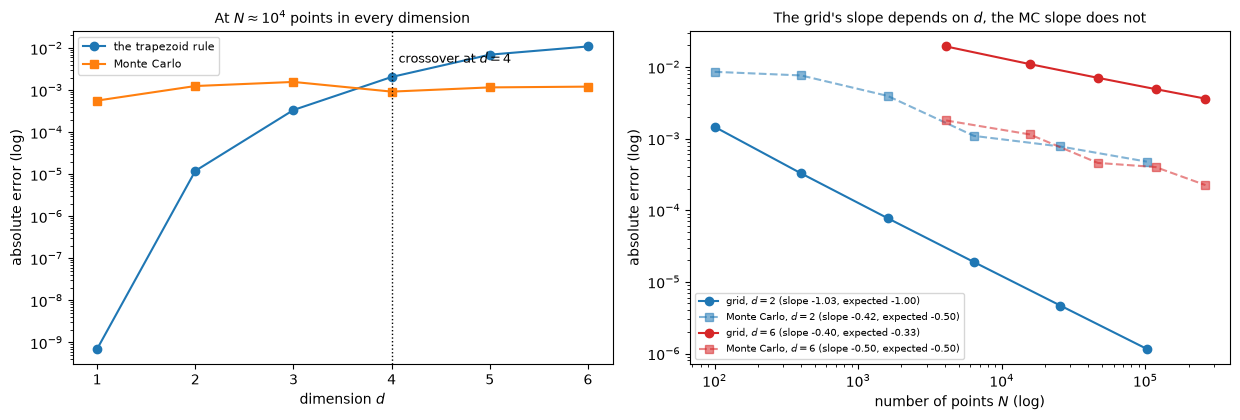

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.semilogy(dims, err_trap, "o-", label="the trapezoid rule")
ax.semilogy(dims, err_mc, "s-", label="Monte Carlo")
ax.axvline(4, color="k", ls=":", lw=1)
ax.text(4.07, max(err_trap) * 0.4, "crossover at $d = 4$", fontsize=9)
ax.set_xlabel("dimension $d$")
ax.set_ylabel("absolute error (log)")
ax.set_title("At $N \\approx 10^4$ points in every dimension", fontsize=10)
ax.legend(fontsize=8)

# how the error falls with N at a fixed d (the slope on log-log axes)
ax = axes[1]
REPS = 12
for d, ms, color in ((2, (10, 20, 40, 80, 160, 320), "tab:blue"),
                     (6, (4, 5, 6, 7, 8), "tab:red")):
    Ns = [m**d for m in ms]
    e_l = [abs(trapezoid(d, m) - exact_product(d)) for m in ms]
    e_m = [sum(abs(mc_integral(d, N) - exact_product(d)) for _ in range(REPS)) / REPS for N in Ns]
    slope_t = (math.log(e_l[-1]) - math.log(e_l[0])) / (math.log(Ns[-1]) - math.log(Ns[0]))
    slope_m = (math.log(e_m[-1]) - math.log(e_m[0])) / (math.log(Ns[-1]) - math.log(Ns[0]))
    ax.loglog(Ns, e_l, "o-", color=color, label=f"grid, $d={d}$ (slope {slope_t:.2f}, expected {-2/d:.2f})")
    ax.loglog(Ns, e_m, "s--", color=color, alpha=0.55,
              label=f"Monte Carlo, $d={d}$ (slope {slope_m:.2f}, expected -0.50)")
ax.set_xlabel("number of points $N$ (log)")
ax.set_ylabel("absolute error (log)")
ax.set_title("The grid's slope depends on $d$, the MC slope does not", fontsize=10)
ax.legend(fontsize=7, loc="lower left")

plt.tight_layout()
plt.show()

The left-hand plot is that prediction, measured: up to three dimensions the grid wins, from four on
Monte Carlo does, and the crossover sits exactly where counting the exponents said it would.

The right-hand plot shows **why**. The slope of the trapezoid curve on log-log axes is $-2/d$, so it
flattens towards horizontal as the dimension grows. The Monte Carlo slope stays $-1/2$ throughout —
the dimension does not interest it.

Two remarks, so the picture does not invite too simple a conclusion:

- **Smoothness counts.** Quadrature feeds on the smoothness of the integrand. For a non-smooth
  function (a kink, a singularity, the indicator of a complicated region) its order collapses even in
  a low dimension, and Monte Carlo wins sooner.
- **The "dimension" need not be geometric.** The insurance simulation from exercise 2 is really an
  integral over $N = 365$ random numbers. There is no way it could be done on a grid.

## 3. Dependent realizations

Everywhere in the course the error bar rests on the formula

$$D\,\bar\xi_N = \frac{\sigma^2}{N},$$

which holds **only for independent** samples. When the samples are dependent — and that happens
whenever the state is generated from the previous one (Markov chains, MCMC, a queue simulated in
time) — the real variance is different:

$$D\,\bar\xi_N = \frac{\sigma^2}{N}\Big(1 + 2\sum_{\ell=1}^{\infty}\rho_\ell\Big) \;=\; \frac{\sigma^2}{N}\cdot\tau,$$

where $\rho_\ell$ is the autocorrelation at lag $\ell$ and $\tau$ is the **integrated autocorrelation
time**. For positively correlated samples $\tau > 1$, so the real error is **larger** than the naive
one.

Let us try it on an AR(1) sequence, $x_t = \varphi x_{t-1} + \varepsilon_t$, where
$\tau = \frac{1+\varphi}{1-\varphi}$ can be computed exactly.

In [5]:
def ar1(N, phi, sigma=1.0):
    '''The sequence x_t = phi*x_{t-1} + noise; starting from the stationary distribution avoids the transient.'''
    x = random.gauss(0, sigma / math.sqrt(1 - phi * phi))
    out = []
    for _ in range(N):
        x = phi * x + random.gauss(0, sigma)
        out.append(x)
    return out


def naive_error(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((v - m) ** 2 for v in xs) / (n - 1)
    return math.sqrt(var / n)


def block_error(xs, B=500):
    '''The method of block averages: blocks of length B are almost independent.'''
    nb = len(xs) // B
    blocks = [sum(xs[i * B:(i + 1) * B]) / B for i in range(nb)]
    m = sum(blocks) / nb
    var = sum((v - m) ** 2 for v in blocks) / (nb - 1)
    return math.sqrt(var / nb)


N = 100_000
print(f"{'φ':>6s} {'naive error':>14s} {'by blocks':>12s} {'ratio':>8s} {'√τ (theory)':>13s}")
phis, ratios, theory = [], [], []
for phi in (0.0, 0.3, 0.6, 0.8, 0.9, 0.95):
    xs = ar1(N, phi)
    a, b = naive_error(xs), block_error(xs)
    t = math.sqrt((1 + phi) / (1 - phi))
    phis.append(phi); ratios.append(b / a); theory.append(t)
    print(f"{phi:>6.2f} {a:>14.5f} {b:>12.5f} {b / a:>8.2f} {t:>13.2f}")

     φ    naive error    by blocks    ratio   √τ (theory)
  0.00        0.00316      0.00342     1.08          1.00
  0.30        0.00331      0.00449     1.35          1.36
  0.60        0.00396      0.00797     2.01          2.00
  0.80        0.00525      0.01666     3.18          3.00
  0.90        0.00721      0.03359     4.66          4.36
  0.95        0.01017      0.06021     5.92          6.24


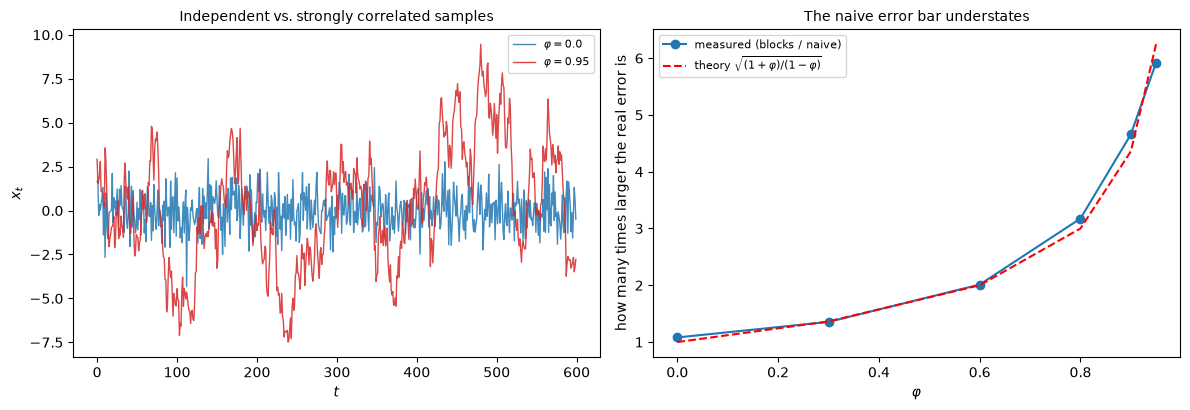

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
for phi, color in ((0.0, "tab:blue"), (0.95, "tab:red")):
    ax.plot(ar1(600, phi), lw=1, color=color, alpha=0.85, label=f"$\\varphi = {phi}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$x_t$")
ax.set_title("Independent vs. strongly correlated samples", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(phis, ratios, "o-", label="measured (blocks / naive)")
ax.plot(phis, theory, "r--", label=r"theory $\sqrt{(1+\varphi)/(1-\varphi)}$")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel("how many times larger the real error is")
ax.set_title("The naive error bar understates", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The left-hand plot shows what dependence means: at $\varphi = 0.95$ the sequence "crawls" — the
neighbouring values are almost the same, so a hundred samples carry less information than a hundred
independent ones.

The right-hand plot puts a number on it. At $\varphi = 0.95$ the real error is roughly **six times**
larger than the naive formula claims. Anyone who believes the formula will report a confidence
interval six times too narrow — and will be confident about something that is not true.

How to defend against it:

1. **Block averages.** Split the run into blocks longer than the correlation time and treat their
   averages as independent samples. Simple and reliable.
2. **Thinning** (taking every $k$-th sample). It works, but it throws away information needlessly;
   blocks are better.
3. **Estimate $\tau$** directly from the sum of the autocorrelations and multiply the naive error by
   it.

## Summary

| Question | Answer |
|---|---|
| Can MC only do integrals? | No — anything in the form of an expectation, including a series sum: $\xi = a_K/p_K$ |
| Does MC pay off in 1D? | No. Quadrature is many orders of magnitude better there. |
| From where on does it pay off? | Trapezoid $N^{-2/d}$ vs MC $N^{-1/2}$ ⟹ crossover at **$d = 4$** (Simpson at $d = 8$) |
| And for non-smooth functions? | Sooner — quadrature loses its order, MC does not |
| Does $\sigma^2/N$ always hold? | **No**, only for independent samples. Otherwise $\tau\sigma^2/N$ |
| What to do about it? | Block averages, thinning, or estimate $\tau$ |

The main idea: the strength of Monte Carlo is not accuracy but **indifference to the dimension**. In
one dimension it loses to anything; in a hundred dimensions it has no competition.

### Try it yourself

1. Estimate $\sum 1/k^3$ by the same method. Which $p_k$ do you choose to keep the estimator bounded?
2. Try a geometric $p_k$, $p_k = 2^{-k}$, for $\sum 1/k^2$. Compute the variance of the estimator and
   explain why it is so much worse.
3. Replace the trapezoid rule with Simpson's and verify that the crossover moves to $d = 8$.
4. Integrate a non-smooth function — $\mathbf 1[\sum x_i < d/2]$, say — and find where the crossover
   is now.
5. In the error comparison, measure the slopes of the lines on log-log axes and compare them with
   $-2/d$ and $-1/2$.
6. For AR(1) with $\varphi = 0.9$, find out how long the blocks have to be before the error estimate
   stops growing with the block length.